# 第0回 動作確認

**このノートブックの役目**：教材を進める準備ができているかを確かめます。上から順に実行して、最後のセルに「準備完了」と出れば、第1回に進めます。

**使い方**：上のセルから順に `Shift + Enter` で実行していきます。コードを書き換える必要はありません。

**確かめること**

1. ライブラリが入っていて、読み込める
2. データを取得できる
3. グラフに日本語を表示できる
4. 小さなモデルを学習できる

**所要時間**：5〜10分。最後の学習のセルに数分かかります。

環境の作り方は、解説ページの「第0回 環境構築」を見てください。


> **この教材について**
>
> - PyMC-Marketing の公式ケーススタディ「[MMM End-to-End Case Study](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_case_study.html)」を、日本語で順に学べるように組み立て直した教材です（作成：Birdwing Technologies合同会社）。
> - コードは本家（Apache License 2.0）をもとに改変しています。解説・図・小課題は独自に加えたものです。
> - データは本家と同じ、公開されている学習用のデータです。
> - 解説ページと全体の目次：<https://bwtech.co.jp/learn/mmm/00-setup>

## 0. 準備

最初のセルは、どの回にも共通の準備です。**Google Colab でも、自分のPCでも、そのまま実行できます。**

- データがなければダウンロードします（約80KB）
- グラフに日本語を表示できるようにします
- Google Colab のときだけ、必要なライブラリを入れます（数分かかります）

In [1]:
# ===== 共通の準備（Google Colab でも、自分のPCでも、このまま実行できます） =====
import subprocess, sys, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- g++（計算を速くする部品）がない環境では、その旨を PyTensor に伝える（WARNING が短くなる） ---
import os, shutil
if shutil.which("g++") is None:
    os.environ["PYTENSOR_FLAGS"] = "cxx="

# --- Colab のときだけ、ライブラリを入れる（数分かかります） ---
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymc-marketing==0.19.2", "nutpie==0.16.8"], check=True)

# --- ファイルの置き場所 ---
BASE_DIR = Path("/content/mmm-pymc") if IN_COLAB else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "case_study_data.csv"

# --- データの取得（なければダウンロードする） ---
DATA_URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/0.19.2/data/case_study_data.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# --- グラフの日本語フォント ---
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_japanese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Meiryo", "Yu Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    # 日本語フォントが見つからないとき（Colab など）は、フォント入りのパッケージを入れる
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=True)
    import matplotlib_fontja  # 読み込むだけで日本語フォント（IPAexGothic）が設定される
    return "IPAexGothic"

font_name = setup_japanese_font()
plt.rcParams["axes.unicode_minus"] = False    # マイナス記号の文字化けを防ぐ

print("実行環境:", "Google Colab" if IN_COLAB else "自分のPC")
print("データ:", DATA_PATH.relative_to(BASE_DIR).as_posix(), "（取得済み）")
print("日本語フォント:", font_name)

実行環境: 自分のPC
データ: data/case_study_data.csv （取得済み）
日本語フォント: Meiryo


## 1. ライブラリを読み込む

初回は30秒ほどかかります。

自分のPC（Windows）では `g++ not available` という WARNING が1行出ることがあります。計算を速くする部品（C++ のコンパイラ）が入っていないという知らせで、この教材では別の方法で速くしているので、**無視してかまいません**。


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import arviz as az
import pymc as pm
import pymc_marketing
import nutpie

from pymc_extras.prior import Prior
from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation
from pymc_marketing.mmm.multidimensional import MMM

print("Python        :", sys.version.split()[0])
print("pymc-marketing:", pymc_marketing.__version__)
print("pymc          :", pm.__version__)
print("nutpie        :", nutpie.__version__)
print("numpy         :", np.__version__)
print("pandas        :", pd.__version__)


WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


Python        : 3.11.9
pymc-marketing: 0.19.2
pymc          : 5.28.5
nutpie        : 0.16.8
numpy         : 2.4.6
pandas        : 3.1.1


**確かめ方**：エラーが出ずに、バージョンが表示されれば合格です。

この教材は次の組み合わせで動作を確かめています。違っていても動くことはありますが、結果の数字が少し変わることがあります。

| ライブラリ | 確かめた版 |
|---|---|
| Python | 3.11 |
| pymc-marketing | 0.19.2 |
| pymc | 5.28.5 |
| nutpie | 0.16.8 |


## 2. データを読み込む

最初のセルで取得したデータを読み込みます。1行が1週間です。


In [3]:
raw_df = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])

print("行数（週の数）:", len(raw_df))
print("列数:", raw_df.shape[1])
print("期間:", raw_df["wk_strt_dt"].min().date(), "〜", raw_df["wk_strt_dt"].max().date())
raw_df[["wk_strt_dt", "sales", "mdsp_vidtr", "mdsp_dm"]].head(3)


行数（週の数）: 209
列数: 80
期間: 2014-08-03 〜 2018-07-29


,wk_strt_dt,sales,mdsp_vidtr,mdsp_dm
0,2014-08-03,72051457.64,216725.59,678410.26
1,2014-08-10,78794770.54,108919.26,661097.71
2,2014-08-17,70071185.56,74032.19,1874338.43


**確かめ方**：行数が 209、列数が 80 なら合格です。


## 3. グラフに日本語を表示する


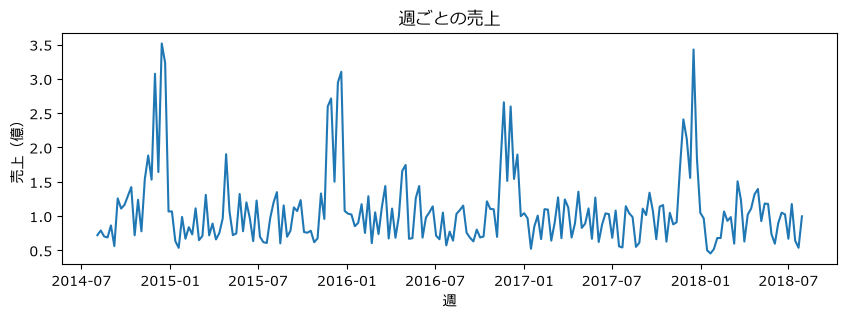

In [4]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(raw_df["wk_strt_dt"], raw_df["sales"] / 1e8)
ax.set_title("週ごとの売上")
ax.set_xlabel("週")
ax.set_ylabel("売上（億）");


**確かめ方**：タイトルと軸の文字が、日本語で読めれば合格です。□□□ のような四角になっていたら、日本語フォントが使えていません（解説ページの「つまずきやすい点」を見てください）。


## 4. 小さなモデルを学習する

教材の本番（第4回）と同じ形のモデルを、**ごく短い設定**で学習します。目的は「最後まで動くか」の確認だけなので、結果の数字に意味はありません。

- 数分かかります。進み具合が表示されます
- 初回は、計算の準備（コンパイル）に1〜2分かかってから動き始めます


In [5]:
channel_names = {"mdsp_dm": "DM", "mdsp_vidtr": "TV", "mdsp_on": "ディスプレイ"}
channel_columns = list(channel_names.values())
date_column, target_column = "wk_strt_dt", "sales"

data_df = raw_df[[date_column, target_column, *channel_names.keys()]].rename(columns=channel_names)
X, y = data_df.drop(columns=target_column), data_df[target_column]

mmm = MMM(
    date_column=date_column,
    target_column=target_column,
    channel_columns=channel_columns,
    adstock=GeometricAdstock(l_max=6),
    saturation=LogisticSaturation(),
    yearly_seasonality=2,
)

# 学習（ごく短い設定：2チェーン × 300回）
mmm.fit(X, y, chains=2, tune=300, draws=300, nuts_sampler="nutpie", random_seed=42);


Progress,Draws,Divergences,Step Size,Gradients/Draw
,600,0,0.23,31
,600,4,0.27,15


Output()

In [6]:
posterior = mmm.idata["posterior"]
n_samples = posterior.sizes["chain"] * posterior.sizes["draw"]
alpha = posterior["adstock_alpha"].mean(("chain", "draw")).to_series().round(2)

print("集まったサンプルの数:", n_samples)
print("adstock の α（チャネルごとの平均）")
print(alpha.to_string())
print()
print("✅ 準備完了です。第1回に進んでください。" if n_samples == 600 else "⚠️ サンプルの数が想定と違います。")


集まったサンプルの数: 600
adstock の α（チャネルごとの平均）
channel
DM        0.31
TV        0.34
ディスプレイ    0.25

✅ 準備完了です。第1回に進んでください。


**確かめ方**：「✅ 準備完了です」と出れば合格です。α の値は実行のたびに少し変わります。

うまくいかなかったときは、解説ページの「つまずきやすい点」を見てください。
